# 02 · Datos sintéticos y supuestos no financieros

Este cuaderno muestra el "sistema administrativo" de Seguros Barú: las pólizas, primas, siniestros, pagos, reservas de caso y gastos de 2023 a 2025. Todo se genera con una semilla fija (`assumptions.SEED`) y con parámetros sintéticos; no se usa ningún dato de clientes reales.

Hay tres clases de números y conviene no confundirlas, porque IFRS 17 exige que la medición use estimaciones insesgadas (par. 33(a), B37–B38):

1. **Tarificación:** las bases con las que se fijaron las primas. Solo determinan las primas.
2. **Mejor estimación:** los supuestos de valuación en cada cierre. Cambian únicamente con la evidencia de cada año (B54–B57).
3. **Verdad simulada:** los parámetros con los que el simulador genera la experiencia "real". El motor de valuación nunca los lee; solo ve los registros, y los lee tal como se conocían en cada cierre (`data.as_of`).

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, '../src')
pd.set_option('display.float_format', lambda x: f'{x:,.0f}' if abs(x) >= 100 else f'{x:,.4f}')
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)
from ifrs17 import assumptions as A
from ifrs17.data import load
from ifrs17.mortality import cso1980
import matplotlib.pyplot as plt

## Mortalidad: CSO 1980 y factor de experiencia

La base es la tabla CSO 1980 por sexo, edad al cumpleaños más cercano (tablas 42 y 36 de la Society of Actuaries). La mejor estimación inicial es 75% de la tabla con una mejora de 1% anual (B49–B50, B58); la tarifa usó 80% sin mejora, lo que deja un margen implícito que IFRS 17 traslada al CSM.

,M,F
age,,
30,0.0017,0.0014
40,0.0030,0.0024
50,0.0067,0.0050
60,0.0161,0.0095
70,0.0395,0.0221


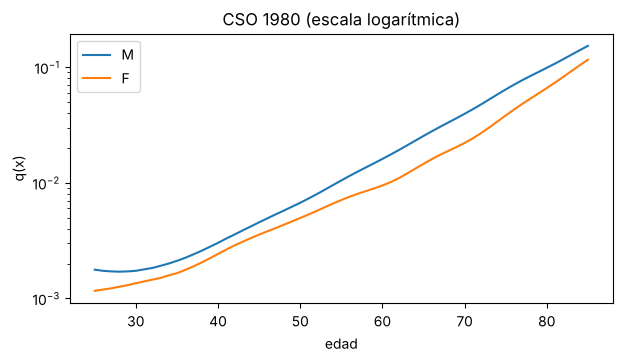

In [2]:
t = cso1980()
ax = t.loc[25:85].plot(logy=True, figsize=(7, 3.5), title='CSO 1980 (escala logarítmica)')
ax.set_xlabel('edad'); ax.set_ylabel('q(x)')
t.loc[[30, 40, 50, 60, 70]]

## El portafolio emitido

Cada año se emiten 3.000 pólizas de vida temporal, 1.500 de vida con ahorro, 20.000 de autos, 8.000 de incendio/hogar y 150 obras de construcción. En vida temporal el canal promocional (20% de descuento) vende en 2023 y 2024, y en 2025 se retarifica el segmento de edades 50+ con suma asegurada alta.

In [3]:
vt = load('vt_policies')
resumen = vt.groupby(['issue_year', 'channel']).agg(polizas=('policy_id', 'size'), prima=('annual_premium', 'sum'),
                                                    suma_media=('sum_insured', 'mean'))
resumen

polizas     prima  suma_media
issue_year channel                                    
2023       agentes          1940 2,240,677     176,629
           bancaseguros      600   660,555     170,383
           promo             460   429,109     174,380
2024       agentes          1982 2,256,472     178,837
           bancaseguros      598   671,715     177,751
           promo             420   360,226     171,155
2025       agentes          2070 2,434,933     174,261
           bancaseguros      930 1,127,154     178,661

In [4]:
pc_resumen = []
for linea in ('auto', 'inc', 'trc'):
    p = load(f'{linea}_policies')
    pc_resumen.append(p.groupby(['line', 'segment', 'issue_year']).agg(polizas=('policy_id', 'size'), prima=('premium', 'sum')))
pd.concat(pc_resumen)

polizas      prima
line segment        issue_year                    
AUTO flotas         2023           1500  1,355,160
                    2024           1500  1,379,616
                    2025           1500  1,484,538
     particulares   2023          18500 10,851,928
                    2024          18500 11,088,704
                    2025          18500 11,330,430
INC  hogar_comercio 2023           8000  3,993,772
                    2024           8000  4,068,924
                    2025           8000  4,154,980
TRC  construccion   2023            150  3,463,890
                    2024            150  3,392,136
                    2025            150  3,087,678

## Experiencia: siniestros y caducidad

El simulador genera muertes y caducidades mes a mes, y siniestros de daños con frecuencia Poisson, severidad lognormal, retraso de reporte y patrón de pago. La responsabilidad civil de autos paga según los patrones de la industria del CAS Loss Reserving Database (Schedule P), y los daños propios, incendio y construcción con retrasos cortos.

La tabla siguiente compara las muertes reportadas con las esperadas por la CSO 1980 sin factor. El segmento de edades 50+ con suma alta tiene pocas muertes, así que su experiencia propia es poco creíble; por eso la mejor estimación combina la experiencia propia con el estudio del reasegurador (B41(c), B56–B57).

In [5]:
from ifrs17.experience import mortality_study
pd.concat([mortality_study('vt', c) for c in A.CLOSINGS])

,closing,segment,exposure_years,deaths,expected_cso80,own_factor,credibility,external_study,best_estimate_factor
0,2023-12-31,default,"1,572",6,5.7791,1.0382,0.0745,0.7500,0.7715
1,2023-12-31,older_high_si,50.0833,0,0.4099,0.0000,0.0000,0.7500,0.7500
0,2024-12-31,default,"5,894",16,21.9251,0.7298,0.1216,0.7500,0.7475
1,2024-12-31,older_high_si,191,0,1.5577,0.0000,0.0000,1.1500,1.1500
0,2025-12-31,default,"12,865",33,48.4546,0.6810,0.1746,0.7500,0.7380
1,2025-12-31,older_high_si,411,3,3.4084,0.8802,0.0527,0.8500,0.8516


In [6]:
claims = load('auto_claims')
claims['ocurrencia'] = claims['occurrence_date'].dt.year
claims.pivot_table(index=['segment', 'coverage'], columns='ocurrencia', values='ultimate', aggfunc=['count', 'mean']).round(0)

count              mean            
ocurrencia             2023  2024  2025  2023  2024  2025
segment      coverage                                    
flotas       PD         119   243   280 1,791 2,217 2,497
             RC          34    58    74 4,411 4,872 8,664
particulares PD         833  1664  1727 1,749 1,794 1,912
             RC         271   555   527 8,059 9,181 7,523

La severidad media de daños propios de flotas sube desde 2024: es la inflación de repuestos que el guion del memo (sección 12) usa para volver onerosas las flotas. La aseguradora la conoce por un índice de precios de mercado (B44), que el motor usa en sus estimaciones desde el cierre de 2024.

## Patrones de pago de la industria

Los patrones vienen del CAS Loss Reserving Database con el paquete `chainladder` (`scripts/build_claims_patterns.py`). Los factores se calculan ponderados por volumen sobre el total de la industria; el coeficiente de variación de la reserva por tamaño de compañía sale de un ajuste de Mack, y alimenta el ajuste por riesgo del LIC.

In [7]:
pat = pd.read_csv('../data/processed/claims_patterns.csv')
pat.pivot(index='development_year', columns='line', values='cumulative_paid')

line,comauto,ppauto
development_year,,
1,0.2609,0.3907
2,0.5336,0.7059
3,0.7214,0.8470
4,0.8468,0.9223
5,0.9213,0.9618
6,0.9583,0.9815
7,0.9784,0.9913
8,0.9874,0.9964
9,0.9934,0.9991


In [8]:
pd.read_csv('../data/processed/claims_cv.csv')

,line,companies,a,b,median_cv,units
0,ppauto,96,0.2398,-0.2420,0.1223,reserve in USD thousands
1,comauto,92,1.3869,-0.3199,0.3088,reserve in USD thousands
